# ECSE 551 Assignment 1 — Task 3: stock return prediction

This notebook predicts the **next trading day's volatility-adjusted return** for 100 S&P 500 constituents per day. It deliberately excludes the two sentiment files. It compares a simple 20-day per-stock linear trend with a pooled sparse linear regression (Lasso). The evaluation period is 2011–2013.

**Run from top to bottom** with this notebook in the same directory as `eq_returns.csv`, `eq_indicator.csv`, and `eq_stock_metadata.csv`. The notebook writes its figures to `task3_results/`. All tables and figures are also displayed in the notebook.

At each prediction date, the code selects 50 Information Technology stocks, up to 50 Energy stocks, and enough Health Care stocks to reach 100. Telecommunication Services is a final fallback. Selection uses only membership and return history available on the prediction date. The target and evaluation data are never used for selecting stocks.

## 1. Imports and settings

The 2011–2013 period is reserved for testing. Data from 2000–2007 trains the model, while 2008–2010 is used only to choose Lasso's penalty. Earlier returns are retained to initialize historical averages. The GICS codes are read as strings so their digits remain intact.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
RESULTS = ROOT / "task3_results"
RESULTS.mkdir(exist_ok=True)

TRAIN_START, TRAIN_END = "2000-01-01", "2007-12-31"
VALID_START, VALID_END = "2008-01-01", "2010-12-31"
TEST_START, TEST_END = "2011-01-01", "2013-12-31"
BETA_MEAN, BETA_VARIANCE = 0.98, 0.94
MIN_DAILY_VOL = 0.005

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.grid": True, "grid.alpha": 0.25})
print("Data files and task3_results/ are located next to this notebook.")

Data files and task3_results/ are located next to this notebook.


## 2. Load returns, index membership, and stock metadata

Each wide CSV has one row per trading date and one column per permanent stock identifier (`permno`). We read only the four sectors used in the selection rule. A blank return remains missing: it is never interpreted as a zero return. The metadata contains duplicate `permno` rows; exact duplicates are removed, and stocks with conflicting GICS codes are excluded because their sector is ambiguous. Nonstandard GICS prefixes are also outside the chosen sectors.

In [2]:
metadata = pd.read_csv(ROOT / "eq_stock_metadata.csv", dtype={"permno": str, "gics": str})
conflicting_ids = metadata.groupby("permno")["gics"].nunique()
conflicting_ids = conflicting_ids.index[conflicting_ids > 1].tolist()
metadata = metadata.loc[~metadata["permno"].isin(conflicting_ids)].drop_duplicates("permno")
metadata["sector"] = metadata["gics"].str[:2]
SECTORS = {"45": "Information Technology", "10": "Energy",
           "35": "Health Care", "50": "Telecommunication Services"}
metadata = metadata.loc[metadata["sector"].isin(SECTORS)].set_index("permno")
stock_ids = metadata.index.tolist()

returns = pd.read_csv(ROOT / "eq_returns.csv", usecols=["date"] + stock_ids,
                      index_col="date", parse_dates=True).sort_index()
indicator = pd.read_csv(ROOT / "eq_indicator.csv", usecols=["date"] + stock_ids,
                        index_col="date", parse_dates=True, dtype=np.int8).sort_index()
indicator = indicator.reindex(index=returns.index, columns=returns.columns)
metadata = metadata.reindex(returns.columns)

assert returns.index.is_unique and returns.columns.is_unique
assert returns.index.equals(indicator.index) and returns.columns.equals(indicator.columns)
assert not metadata["sector"].isna().any().item()
print("Excluded ambiguous sector IDs:", conflicting_ids)
print(f"Trading dates: {len(returns):,}; candidate stocks: {returns.shape[1]}")
print(f"Dates: {returns.index.min().date()} to {returns.index.max().date()}")
print("Candidate stocks by sector:")
print(metadata["sector"].map(SECTORS).value_counts().to_string())

Excluded ambiguous sector IDs: ['12431', '25232', '32707', '45356']
Trading dates: 8,577; candidate stocks: 404
Dates: 1980-01-02 to 2013-12-31
Candidate stocks by sector:
sector
Information Technology        163
Health Care                   109
Energy                        101
Telecommunication Services     31


## 3. Estimate historical volatility and adjust returns

Following the assignment's equations (2) and (3), two exponential moving averages estimate the changing mean and volatility for each stock. The adjusted return for day $t$ is $r_t / \hat\sigma_{t-1}$: its denominator is estimated **before** day $t$. The small volatility floor prevents division by zero or extremely small initial estimates. A missing raw return stays missing.

The target for a prediction made after the close of day $t$ will be the adjusted return on the **next trading day**. The observed return on day $t$ is available for making that prediction.

In [3]:
mean_est = returns.ewm(alpha=1 - BETA_MEAN, adjust=False, ignore_na=True).mean()
innovations = returns - mean_est
variance_est = innovations.pow(2).ewm(
    alpha=1 - BETA_VARIANCE, adjust=False, ignore_na=True
).mean()
prior_volatility = np.sqrt(variance_est.shift(1)).clip(lower=MIN_DAILY_VOL)
adjusted_returns = returns / prior_volatility
adjusted_returns = adjusted_returns.replace([np.inf, -np.inf], np.nan)

print("Example: first five available adjusted returns for one stock")
example_stock = returns.columns[0]
print(pd.DataFrame({"raw_return": returns[example_stock],
                    "prior_volatility": prior_volatility[example_stock],
                    "adjusted_return": adjusted_returns[example_stock]}).dropna().head().to_string())

Example: first five available adjusted returns for one stock
            raw_return  prior_volatility  adjusted_return
date                                                     
1986-03-06   -0.057143          0.005000       -11.428600
1986-03-07    0.008658          0.006127         1.413192
1986-03-10    0.000000          0.011452         0.000000
1986-03-11    0.042918          0.013409         3.200725
1986-03-12   -0.016461          0.021937        -0.750387


## 4. Build historical features and a per-stock trend baseline

The baseline fits a straight line through each stock's **last 20 adjusted daily returns** and extrapolates it one trading day. This is a rolling ordinary least-squares forecast, implemented with rolling sums instead of thousands of separate model objects. It is a benchmark, not an assumption that stock returns really follow a straight line.

Lasso receives the baseline forecast together with recent adjusted returns, 5/20/60-day mean returns, 20-day return variation, current historical volatility, and sector indicators. All these inputs are known by the end of the prediction day. No next-day return is used as an input.

In [4]:
def rolling_linear_forecast(frame, window=20):
    # Fit y_j = intercept + slope*j for j=0,...,window-1, then predict j=window.
    time = pd.Series(np.arange(len(frame), dtype=float), index=frame.index)
    sum_y = frame.rolling(window, min_periods=window).sum()
    sum_time_y = frame.mul(time, axis=0).rolling(window, min_periods=window).sum()
    center_time = time - (window - 1) / 2
    denominator = window * (window**2 - 1) / 12
    slope = sum_time_y.sub(sum_y.mul(center_time, axis=0)) / denominator
    return sum_y / window + slope * (window + 1) / 2

features = {
    "last_return": adjusted_returns,
    "mean_5": adjusted_returns.rolling(5, min_periods=5).mean(),
    "mean_20": adjusted_returns.rolling(20, min_periods=20).mean(),
    "mean_60": adjusted_returns.rolling(60, min_periods=60).mean(),
    "trend_20": rolling_linear_forecast(adjusted_returns, 20),
    "variation_20": adjusted_returns.rolling(20, min_periods=20).std(),
    "volatility_today": np.sqrt(variance_est),
}
NUMERIC_FEATURES = list(features)
feature_available = pd.DataFrame(True, index=returns.index, columns=returns.columns)
for feature_frame in features.values():
    feature_available &= feature_frame.notna() & np.isfinite(feature_frame)
print("Historical features:", NUMERIC_FEATURES)

Historical features: ['last_return', 'mean_5', 'mean_20', 'mean_60', 'trend_20', 'variation_20', 'volatility_today']


## 5. Select 100 stocks per prediction day without looking ahead

A stock must be an S&P 500 constituent on the **prediction day** and have 60 consecutive days of observed returns. Within each sector, stocks are ranked by the number of observed member-day returns in the past 252 trading days; `permno` breaks ties. This rule is fixed before seeing next-day results. It helps keep the selection reproducible and avoids picking stocks because they later perform well.

The next-day target may still be missing when a stock leaves the index. Such predictions remain in the 100 issued predictions, but cannot be scored; a missing result is never replaced with zero.

In [5]:
member_with_return = indicator.eq(1) & returns.notna()
consecutive_60 = member_with_return.rolling(60, min_periods=60).sum().eq(60)
history_252 = member_with_return.rolling(252, min_periods=1).sum()
eligible = indicator.eq(1) & consecutive_60 & feature_available
sector_ids = {sector: metadata.index[metadata["sector"].eq(sector)].tolist()
              for sector in SECTORS}

blocks = []
for position, date in enumerate(returns.index[:-1]):
    if date < pd.Timestamp(TRAIN_START):
        continue
    next_date = returns.index[position + 1]
    if next_date > pd.Timestamp(TEST_END):
        break
    available_today = eligible.loc[date]
    priority_today = history_252.loc[date]
    picked = []
    for sector, quota in [("45", 50), ("10", 50), ("35", 100), ("50", 100)]:
        candidates = [stock for stock in sector_ids[sector] if available_today[stock]]
        candidates.sort(key=lambda stock: (-priority_today[stock], stock))
        take = min(quota, 100 - len(picked))
        picked.extend(candidates[:take])
        if len(picked) == 100:
            break
    if len(picked) < 100:
        raise ValueError(f"Only {len(picked)} eligible stocks on {date.date()}")

    block = pd.DataFrame({"prediction_date": date, "target_date": next_date,
                          "permno": picked,
                          "sector": metadata.loc[picked, "sector"].to_numpy(),
                          "target": adjusted_returns.loc[next_date, picked].to_numpy()})
    for name, frame in features.items():
        block[name] = frame.loc[date, picked].to_numpy()
    blocks.append(block)

panel = pd.concat(blocks, ignore_index=True)
for sector in SECTORS:
    panel[f"sector_{sector}"] = panel["sector"].eq(sector).astype(int)
MODEL_FEATURES = NUMERIC_FEATURES + [f"sector_{sector}" for sector in SECTORS]

print(f"Prediction days: {len(blocks):,}; predictions: {len(panel):,}")
print("Daily predictions: min =", panel.groupby("target_date").size().min(),
      ", max =", panel.groupby("target_date").size().max())
print("Scorable next-day returns:", int(panel["target"].notna().sum()),
      "of", len(panel))
print("2011–2013 selected stocks per sector (daily minimum/median/maximum):")
test_counts = (panel.loc[panel["target_date"].between(TEST_START, TEST_END)]
               .groupby(["target_date", "sector"]).size().unstack(fill_value=0))
print(test_counts.agg(["min", "median", "max"]).rename(columns=SECTORS).to_string())

Prediction days: 3,520; predictions: 352,000
Daily predictions: min = 100 , max = 100
Scorable next-day returns: 351959 of 352000
2011–2013 selected stocks per sector (daily minimum/median/maximum):
sector  Energy  Health Care  Information Technology
min       33.0         14.0                    50.0
median    34.0         16.0                    50.0
max       36.0         17.0                    50.0


## 6. Split by the **target date**, never randomly

For example, a prediction made on the last trading day of 2010 targets the first trading day of 2011, so it belongs to the **test** set. Splitting by target date avoids accidentally training on a 2011 outcome. The last available day of 2013 has no next-day return in the file and is not included.

In [6]:
train = panel.loc[panel["target_date"].between(TRAIN_START, TRAIN_END)].copy()
valid = panel.loc[panel["target_date"].between(VALID_START, VALID_END)].copy()
test = panel.loc[panel["target_date"].between(TEST_START, TEST_END)].copy()
assert train["target_date"].max() < valid["target_date"].min()
assert valid["target_date"].max() < test["target_date"].min()
assert test.groupby("target_date").size().eq(100).all()
for name, frame in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{name}: {frame.target_date.nunique()} days, {len(frame):,} predictions, "
          f"{frame.target.notna().sum():,} scorable")

Train: 2009 days, 200,900 predictions, 200,874 scorable
Validation: 757 days, 75,700 predictions, 75,689 scorable
Test: 754 days, 75,400 predictions, 75,396 scorable


## 7. Define the backtest and assignment metrics

Predictions are centered to zero across the 100 selected stocks each day, reducing a simple long-market bias. They are then divided by their daily absolute sum, giving both methods the same gross exposure for a fair comparison. These weights remain **proportional** to predicted adjusted returns. The daily PnL is the sum of weight times realized next-day adjusted return, as in equations (5)–(6). We do not renormalize after discovering a missing next-day return.

The annualized Sharpe ratio follows equation (4), with benchmark return set to zero. Daily Spearman rank correlation checks whether stocks were ordered correctly. The holding-period approximation follows equation (7), using the actual daily strategy weights; absent stocks have weight zero. These are research backtest scores, not cash profits after trading costs.

In [7]:
def add_weights(frame, prediction_column):
    result = frame.copy()
    grouped = result.groupby("target_date")[prediction_column]
    centered = result[prediction_column] - grouped.transform("mean")
    gross = centered.abs().groupby(result["target_date"]).transform("sum")
    result["weight"] = centered.div(gross.where(gross > 0)).fillna(0.0)
    return result


def evaluate(frame, prediction_column):
    weighted = add_weights(frame, prediction_column)
    scored = weighted.loc[weighted["target"].notna()].copy()
    scored["contribution"] = scored["weight"] * scored["target"]
    daily = scored.groupby("target_date").agg(
        pnl=("contribution", "sum"),
        scorable=("target", "size"),
        equal_weight_return=("target", "mean"),
    )
    daily["rank_corr"] = scored.groupby("target_date").apply(
        lambda g: g[prediction_column].rank().corr(g["target"].rank())
        if (len(g) >= 3 and g[prediction_column].nunique() > 1
            and g["target"].nunique() > 1) else np.nan,
        include_groups=False,
    )
    daily["cumulative_pnl"] = daily["pnl"].cumsum()
    daily["cumulative_rank_corr"] = daily["rank_corr"].fillna(0).cumsum()
    pnl_sd = daily["pnl"].std(ddof=1)
    sharpe = daily["pnl"].mean() / pnl_sd * np.sqrt(252) if pnl_sd > 0 else np.nan

    positions = weighted.pivot(index="target_date", columns="permno", values="weight").fillna(0)
    mean_size = positions.abs().iloc[1:].mean(axis=0)
    mean_change = positions.diff().abs().iloc[1:].mean(axis=0)
    stock_holding = (mean_size / mean_change.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
    holding_days = stock_holding.dropna().mean()
    market_corr = (daily["pnl"].corr(daily["equal_weight_return"])
                   if pnl_sd > 0 and daily["equal_weight_return"].std(ddof=1) > 0
                   else np.nan)
    metrics = {"Sharpe": sharpe, "Mean daily rank corr": daily["rank_corr"].mean(),
               "Approx. holding days": holding_days,
               "Corr. with equal-weight selected stocks": market_corr,
               "Scorable stock-days": int(daily["scorable"].sum()),
               "Min scorable/day": int(daily["scorable"].min())}
    return daily, metrics

valid["trend_prediction"] = valid["trend_20"]
valid_baseline_daily, valid_baseline_metrics = evaluate(valid, "trend_prediction")
print("Validation baseline metrics:")
print(pd.Series(valid_baseline_metrics).round(4).to_string())

Validation baseline metrics:
Sharpe                                        -0.9431
Mean daily rank corr                          -0.0085
Approx. holding days                           2.0230
Corr. with equal-weight selected stocks       -0.1633
Scorable stock-days                        75689.0000
Min scorable/day                              99.0000


## 8. Tune Lasso on 2008–2010, then refit before 2011

`StandardScaler` learns feature means and scales from the training period only. Four L1 penalties are compared on the separate validation period using the assignment's Sharpe metric. Lasso can set weak feature coefficients exactly to zero. After selecting the penalty, the model and scaler are refitted on **all scorable pre-2011 rows**, then used unchanged throughout 2011–2013. This is a fixed-model backtest; a rolling retraining design is possible but is not needed for a leakage-free initial comparison.

In [8]:
train_scored = train.loc[train["target"].notna()]
valid_scored = valid.loc[valid["target"].notna()]
train_scaler = StandardScaler().fit(train_scored[MODEL_FEATURES])
X_train = train_scaler.transform(train_scored[MODEL_FEATURES])
y_train = train_scored["target"].to_numpy()
X_valid = train_scaler.transform(valid[MODEL_FEATURES])

ALPHAS = [0.0001, 0.001, 0.01, 0.05]
tuning_rows = []
for alpha in ALPHAS:
    trial = Lasso(alpha=alpha, max_iter=10000, tol=1e-4)
    trial.fit(X_train, y_train)
    trial_frame = valid.copy()
    trial_frame["prediction"] = trial.predict(X_valid)
    _, trial_metrics = evaluate(trial_frame, "prediction")
    tuning_rows.append({"alpha": alpha,
                        "validation_Sharpe": trial_metrics["Sharpe"],
                        "validation_rank_corr": trial_metrics["Mean daily rank corr"],
                        "nonzero_coefficients": int(np.count_nonzero(trial.coef_))})
tuning = pd.DataFrame(tuning_rows)
print(tuning.round(5).to_string(index=False))
tuning.to_csv(RESULTS / "task3_validation_tuning.csv", index=False)
if tuning["validation_Sharpe"].notna().sum() == 0:
    raise ValueError("All validation strategies have undefined Sharpe; inspect predictions.")
chosen_alpha = float(tuning.loc[tuning["validation_Sharpe"].idxmax(), "alpha"])
print("Chosen alpha:", chosen_alpha)

pretest_scored = pd.concat([train_scored, valid_scored], ignore_index=True)
final_scaler = StandardScaler().fit(pretest_scored[MODEL_FEATURES])
final_model = Lasso(alpha=chosen_alpha, max_iter=10000, tol=1e-4)
final_model.fit(final_scaler.transform(pretest_scored[MODEL_FEATURES]),
                pretest_scored["target"])
coefficients = pd.Series(final_model.coef_, index=MODEL_FEATURES, name="coefficient")
print("Final Lasso coefficients:")
print(coefficients.round(5).to_string())

 alpha  validation_Sharpe  validation_rank_corr  nonzero_coefficients
0.0001            0.62230               0.00752                     9
0.0010            0.67561               0.00826                     9
0.0100            0.89450               0.00819                     3
0.0500                NaN                   NaN                     0
Chosen alpha: 0.01
Final Lasso coefficients:
last_return        -0.00000
mean_5             -0.00000
mean_20            -0.00000
mean_60            -0.00000
trend_20           -0.00373
variation_20       -0.00000
volatility_today   -0.00087
sector_45          -0.00000
sector_10           0.00000
sector_35           0.00000
sector_50           0.00000


## 9. Evaluate both methods on the untouched 2011–2013 test period

A prediction is made for **exactly 100 stocks** on every test day. Missing next-day outcomes are excluded only from scoring, never turned into zero returns and never used to change the day's selected stocks. The same centering and daily exposure rule is applied to both methods.

In [9]:
test["trend_prediction"] = test["trend_20"]
test["lasso_prediction"] = final_model.predict(final_scaler.transform(test[MODEL_FEATURES]))
trend_daily, trend_metrics = evaluate(test, "trend_prediction")
lasso_daily, lasso_metrics = evaluate(test, "lasso_prediction")
metrics = pd.DataFrame({"20-day linear trend": trend_metrics,
                        "Lasso": lasso_metrics})
print(metrics.round(4).to_string())
metrics.to_csv(RESULTS / "task3_test_metrics.csv")
pd.DataFrame({"trend_pnl": trend_daily["pnl"], "lasso_pnl": lasso_daily["pnl"],
              "trend_cumulative_pnl": trend_daily["cumulative_pnl"],
              "lasso_cumulative_pnl": lasso_daily["cumulative_pnl"],
              "trend_rank_corr": trend_daily["rank_corr"],
              "lasso_rank_corr": lasso_daily["rank_corr"]}).to_csv(
                  RESULTS / "task3_test_daily_results.csv")
print("Prediction dates:", test.prediction_date.min().date(), "to", test.prediction_date.max().date())
print("Realized target dates:", test.target_date.min().date(), "to", test.target_date.max().date())

                                         20-day linear trend       Lasso
Sharpe                                               -1.1179      1.3247
Mean daily rank corr                                 -0.0055      0.0089
Approx. holding days                                  2.0331      2.0389
Corr. with equal-weight selected stocks              -0.0901      0.1612
Scorable stock-days                               75396.0000  75396.0000
Min scorable/day                                     99.0000     99.0000
Prediction dates: 2010-12-31 to 2013-12-30
Realized target dates: 2011-01-03 to 2013-12-31


## 10. Plot cumulative PnL

This is the cumulative sum of **out-of-sample daily strategy PnL**, not a fitted stock-price trend. Because both strategies have the same daily gross exposure, the two curves can be compared directly. Negative or flat performance is a valid result and should be reported honestly.

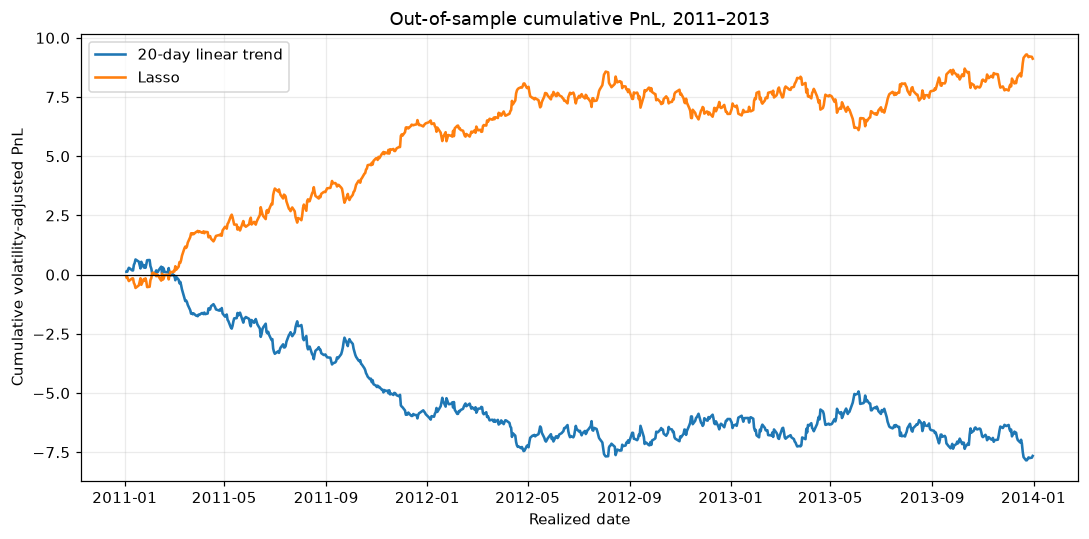

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trend_daily.index, trend_daily["cumulative_pnl"], label="20-day linear trend", linewidth=1.7)
ax.plot(lasso_daily.index, lasso_daily["cumulative_pnl"], label="Lasso", linewidth=1.7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Out-of-sample cumulative PnL, 2011–2013", xlabel="Realized date",
       ylabel="Cumulative volatility-adjusted PnL")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "task3_cumulative_pnl.png")
plt.show()

## 11. Plot cumulative stock-ranking ability

Daily Spearman correlation compares the predicted order of the selected stocks with their actual next-day return order. A rising cumulative curve suggests persistent ranking ability; a falling or flat curve suggests little or negative ability.

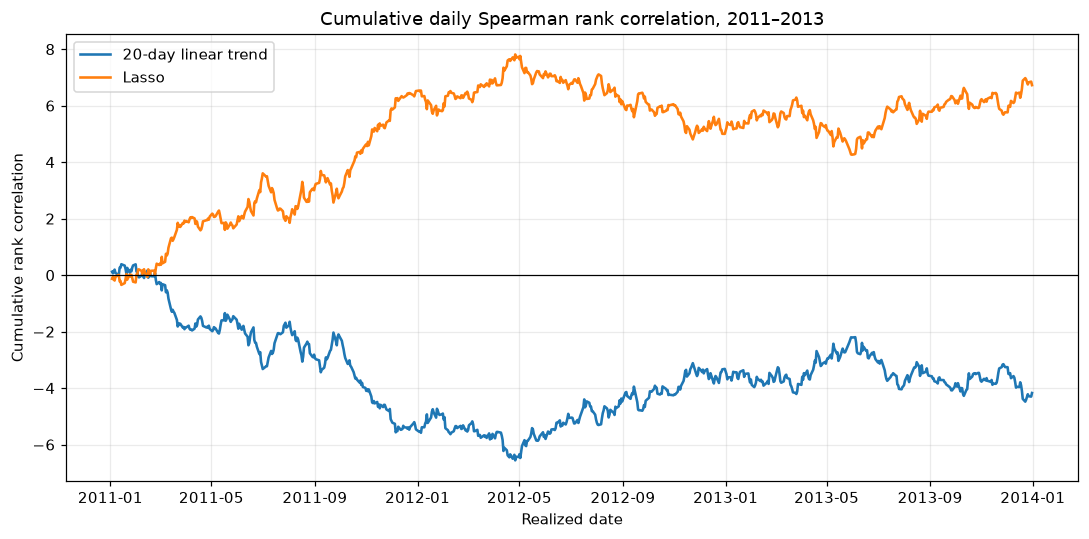

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trend_daily.index, trend_daily["cumulative_rank_corr"], label="20-day linear trend", linewidth=1.7)
ax.plot(lasso_daily.index, lasso_daily["cumulative_rank_corr"], label="Lasso", linewidth=1.7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Cumulative daily Spearman rank correlation, 2011–2013",
       xlabel="Realized date", ylabel="Cumulative rank correlation")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "task3_cumulative_rank_correlation.png")
plt.show()

## 12. Check year-by-year Sharpe ratios and result coverage

An overall Sharpe ratio can hide an inconsistent strategy. The table below shows 2011, 2012, and 2013 separately. Coverage is also checked: 100 predictions were issued each day, but the next-day return of a stock that leaves the index may be unavailable.

Annualized Sharpe by test year:
             20-day linear trend  Lasso
target_date                            
2011                      -2.732  2.937
2012                      -0.089  0.174
2013                      -0.651  0.971
Daily scorable targets: minimum = 99 , median = 100.0 , days below 100 = 4
Overall test Sharpe: trend -1.118; Lasso 1.325.
Lasso mean daily rank correlation: 0.0089; approximate holding period: 2.04 days.
Interpret the overall result alongside individual years; a short holding period means trading costs could materially reduce performance.


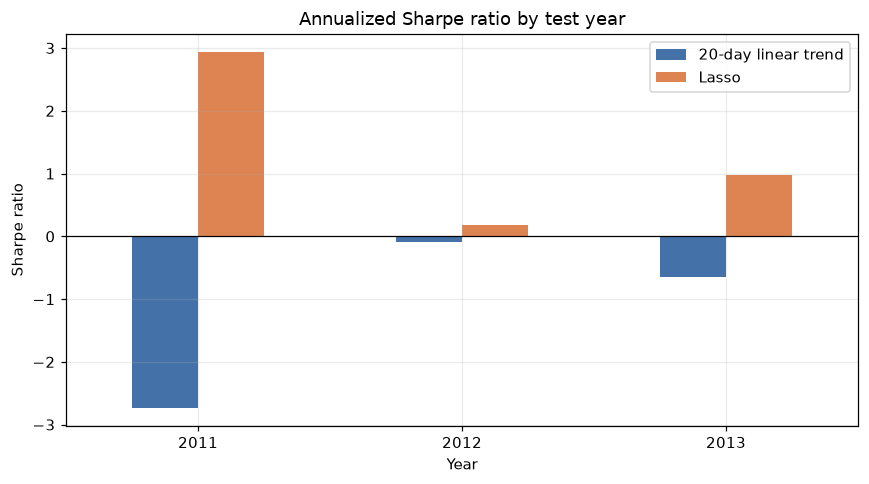

In [12]:
def annual_sharpe(daily):
    return daily["pnl"].groupby(daily.index.year).apply(
        lambda x: x.mean() / x.std(ddof=1) * np.sqrt(252) if x.std(ddof=1) > 0 else np.nan
    )

annual = pd.DataFrame({"20-day linear trend": annual_sharpe(trend_daily),
                       "Lasso": annual_sharpe(lasso_daily)})
print("Annualized Sharpe by test year:")
print(annual.round(3).to_string())
annual.to_csv(RESULTS / "task3_annual_sharpe.csv")
print("Daily scorable targets: minimum =", lasso_daily.scorable.min(),
      ", median =", lasso_daily.scorable.median(),
      ", days below 100 =", int((lasso_daily.scorable < 100).sum()))
print(f"Overall test Sharpe: trend {trend_metrics['Sharpe']:.3f}; "
      f"Lasso {lasso_metrics['Sharpe']:.3f}.")
print(f"Lasso mean daily rank correlation: "
      f"{lasso_metrics['Mean daily rank corr']:.4f}; "
      f"approximate holding period: {lasso_metrics['Approx. holding days']:.2f} days.")
print("Interpret the overall result alongside individual years; "
      "a short holding period means trading costs could materially reduce performance.")

fig, ax = plt.subplots(figsize=(8, 4.5))
annual.plot.bar(ax=ax, rot=0, color=["#4472a8", "#dd8452"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Annualized Sharpe ratio by test year", xlabel="Year", ylabel="Sharpe ratio")
fig.tight_layout()
fig.savefig(RESULTS / "task3_annual_sharpe.png")
plt.show()

## 13. Interpretation and limitations

Compare the **test** curves, overall and annual Sharpe ratios, mean rank correlations, and holding-period estimates above. A high score in only one year is much weaker evidence than a steady pattern. Lasso coefficients near or equal to zero mean the corresponding historical feature contributed little under the chosen penalty. Negative results should be reported rather than concealed.

The backtest has several limits: sentiment signals were intentionally excluded; transaction costs and financing are not modeled; only four GICS sectors are considered, and exactly 100 stocks are selected daily; some issued predictions cannot be scored because the next-day return is missing; the metadata has no historical classification dates; the Lasso model is fixed during the test rather than retrained over time. The curves are research diagnostics, not a deployable trading strategy.

For the assignment report, describe the selection rule, the 2011–2013 chronological test, the volatility adjustment, the tuned penalty, all metrics, and how any LLM assistance was used. The notebook uses only the original CSV files and regenerates every displayed result.